# P4.05 — Can rents be forecast? National real rents and the price-to-rent ratio

**Questions:** RQ10.1 (how prices, rents and affordability evolve over 5 to 10 years; rents were the missing part),
RQ1.3 (real rents). The simulator follows prices and the ownership burden; this notebook asks whether a statistical
forecast of **rents** is worth carrying into it.

**Series (annual, national, 1988 to 2025, 38 points, from `national_annual_long`):**
1. **real rent index** (OECD rent prices, rebased to 2015 = 100, deflated by the project CPI). It is the rent component of
   consumer prices: it covers *all* leases, including old ones whose rent is regulated or frozen, so it moves much more
   slowly than the rent of a new lease;
2. **price-to-rent** (OECD, 2015 = 100): the real price relative to rents, the indicator that makes the two comparable.

**Methods:** the same as `p4_01` (naive, drift, ETS, ARIMA, on logs) without the seasonal naive, which has no meaning on
annual data (`forecasting.ANNUAL_METHODS`; ETS drops its seasonal forms). **Validation:** rolling origin, first origin after
20 years (2007), refitted each year, 1 to 5 years ahead; RMSE, bias and interval coverage.

**Selection rule, per series:** the method with the lowest mean RMSE over 1 to 5 years; ties to the simpler. It is applied
per series, unlike `p4_01`, because here the two series do not agree on whether any model beats no change at all. The rule
was written after a first exploratory look at the validation table; the checks in Step 3 (a shorter first window and
dropping the pandemic origins) are the safeguard against having tuned it.

In [1]:
import numpy as np
import pandas as pd

from pthousing.analysis import forecasting as fc
from pthousing.data import build_panel
from pthousing.viz import charts, style

style.apply_style()
annual = build_panel.read("national_annual_long").set_index("year")
annual.index = pd.PeriodIndex(annual.index, freq="Y")
series = {
    "Real rent index": np.log(annual["rent_real_b2015"].dropna()),
    "Price-to-rent": np.log(annual["price_to_rent_b2015"].dropna()),
}
INITIAL, HORIZON = 20, 5
for name, s in series.items():
    print(f"{name}: {len(s)} years, {s.index[0]} to {s.index[-1]}")

Real rent index: 38 years, 1988 to 2025
Price-to-rent: 38 years, 1988 to 2025


## Step 1 — Rolling-origin validation

In [2]:
results, accuracy, relative = {}, {}, {}
for name, s in series.items():
    results[name] = fc.rolling_origin(
        s, methods=fc.ANNUAL_METHODS, initial=INITIAL, horizon=HORIZON
    )
    accuracy[name] = fc.accuracy(results[name], fc.mase_scale(s, INITIAL))
    relative[name] = fc.relative_to(accuracy[name], "naive")
    print(name, "- RMSE relative to naive, by years ahead")
    print(relative[name].round(2).to_string(), "\n")
tables = pd.concat([a.assign(series=n) for n, a in accuracy.items()], ignore_index=True)
style.save_table(tables.round(4), "p4", "rent_forecast_accuracy_by_horizon")
summary = (
    tables.groupby(["series", "method"])
    .agg(rmse=("rmse", "mean"), bias=("bias", "mean"), coverage80=("coverage80", "mean"),
         coverage95=("coverage95", "mean"))
    .round(3)
    .reset_index()
)  # fmt: skip
style.save_table(summary, "p4", "rent_forecast_accuracy_summary")
summary

Real rent index - RMSE relative to naive, by years ahead
method  ARIMA   ETS  drift  naive
h                                
1        1.09  1.07   0.94    1.0
2        1.25  1.18   0.93    1.0
3        1.45  1.29   0.92    1.0
4        1.37  1.38   0.88    1.0
5        1.15  1.25   0.67    1.0 



Price-to-rent - RMSE relative to naive, by years ahead
method  ARIMA   ETS  drift  naive
h                                
1        0.68  0.78   1.02    1.0
2        0.69  0.82   1.05    1.0
3        0.69  0.83   1.08    1.0
4        0.74  0.87   1.10    1.0
5        0.81  0.94   1.13    1.0 



,series,method,rmse,bias,coverage80,coverage95
0,Price-to-rent,ARIMA,0.123,0.054,0.557,0.885
1,Price-to-rent,ETS,0.145,0.086,0.576,0.785
2,Price-to-rent,drift,0.181,0.103,0.240,0.486
3,Price-to-rent,naive,0.166,0.068,0.215,0.430
4,Real rent index,ARIMA,0.050,0.015,0.803,0.965
5,Real rent index,ETS,0.049,0.012,0.589,0.955
6,Real rent index,drift,0.033,-0.011,0.883,0.977
7,Real rent index,naive,0.039,0.024,0.819,0.977


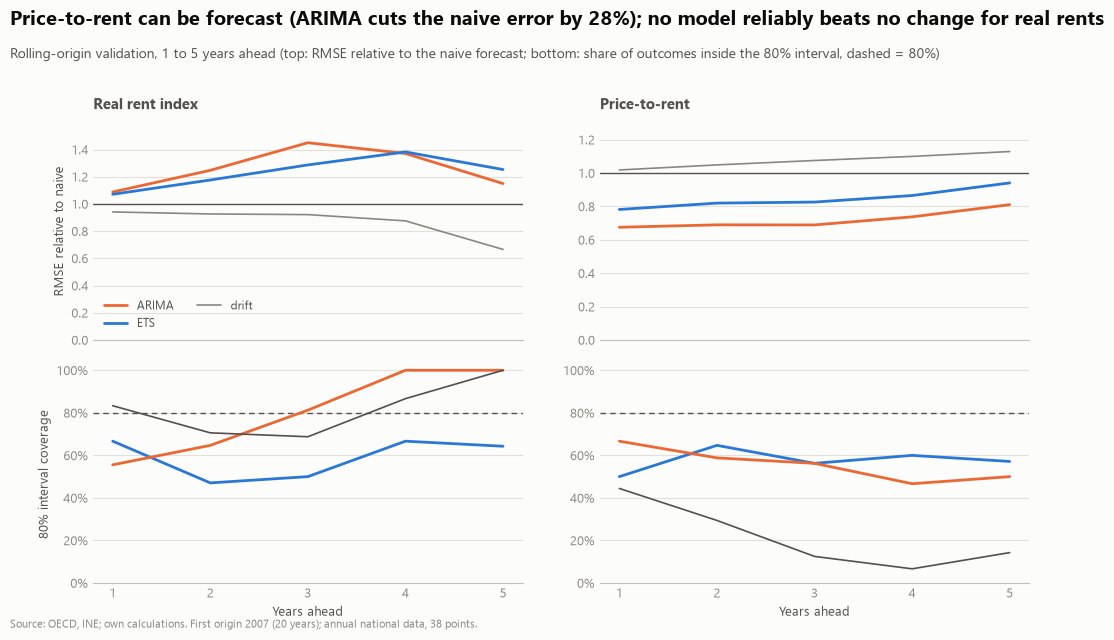

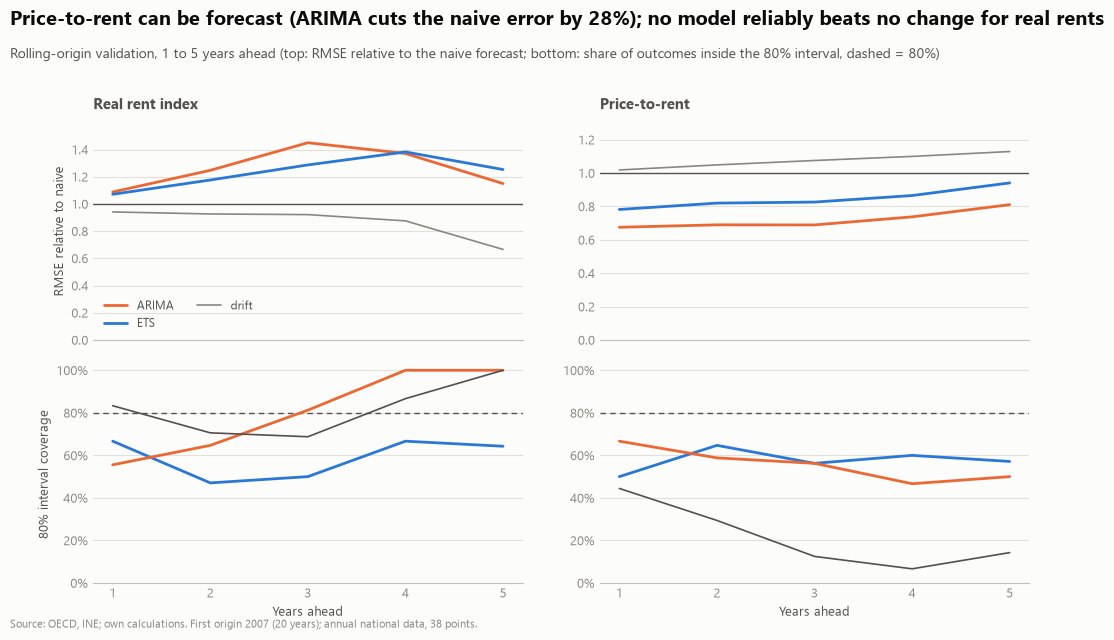

In [3]:
fig = charts.forecast_accuracy(
    [{"title": name, "rel": relative[name], "acc": accuracy[name]} for name in series],
    unit="years",
    note="First origin 2007 (20 years); annual national data, 38 points.",
    source="OECD, INE",
    headline=(
        f"Price-to-rent can be forecast (ARIMA cuts the naive error by {100 * (1 - relative['Price-to-rent']['ARIMA'].mean()):.0f}%);"
        " no model reliably beats no change for real rents"
    ),
)
style.save_fig(fig, "p4", "rent_forecast_accuracy")
fig

## Step 2 — Which method, series by series

In [4]:
mean_rmse = pd.DataFrame({n: a.groupby("method")["rmse"].mean() for n, a in accuracy.items()})
order = {n: mean_rmse[n].sort_values() for n in mean_rmse}
chosen = {n: o.index[0] for n, o in order.items()}
for n, o in order.items():
    print(n, "->", chosen[n], "| mean RMSE", o.round(4).to_dict())

Real rent index -> drift | mean RMSE {'drift': 0.0333, 'naive': 0.0389, 'ETS': 0.0486, 'ARIMA': 0.0496}
Price-to-rent -> ARIMA | mean RMSE {'ARIMA': 0.1231, 'ETS': 0.1446, 'naive': 0.1663, 'drift': 0.1815}


## Step 3 — Is the result stable?
A shorter first window (15 years, origins from 2002) and dropping the origins of 2020 and 2021.

In [5]:
checks = []
covid = (pd.Period("2020", "Y"), pd.Period("2021", "Y"))
for name, s in series.items():
    for initial in (15, 20):
        res = (
            results[name]
            if initial == INITIAL
            else fc.rolling_origin(s, methods=fc.ANNUAL_METHODS, initial=initial, horizon=HORIZON)
        )
        for tag, r in (
            (f"first window {initial} years", res),
            (f"first window {initial} years, without 2020-21 origins", res[~res["origin"].between(*covid)]),
        ):  # fmt: skip
            rel = fc.relative_to(fc.accuracy(r, fc.mase_scale(s, initial)), "naive").mean()
            checks.append(
                pd.DataFrame(
                    {
                        "series": name,
                        "variant": tag,
                        "method": rel.index,
                        "rmse_vs_naive": rel.values,
                    }
                )
            )
checks = pd.concat(checks, ignore_index=True)
stable = checks.pivot_table(
    index=["series", "variant"], columns="method", values="rmse_vs_naive"
).round(2)
style.save_table(stable.reset_index(), "p4", "rent_forecast_variants")
stable

method                                                          ARIMA   ETS  \
series          variant                                                       
Price-to-rent   first window 15 years                            0.73  0.85   
                first window 15 years, without 2020-21 origins   0.77  0.90   
                first window 20 years                            0.72  0.85   
                first window 20 years, without 2020-21 origins   0.76  0.91   
Real rent index first window 15 years                            1.25  1.24   
                first window 15 years, without 2020-21 origins   1.25  1.24   
                first window 20 years                            1.26  1.23   
                first window 20 years, without 2020-21 origins   1.25  1.23   

method                                                          drift  naive  
series          variant                                                       
Price-to-rent   first window 15 years                            1.06    1.0  
                first window 15 years, without 2020-21 origins   1.06    1.0  
                first window 20 years                            1.07    1.0  
                first window 20 years, without 2020-21 origins   1.08    1.0  
Real rent index first window 15 years                            1.03    1.0  
                first window 15 years, without 2020-21 origins   0.97    1.0  
                first window 20 years                            0.87    1.0  
                first window 20 years, without 2020-21 origins   0.78    1.0

## Step 4 — Five-year forecast with the chosen methods
Fitted on all 38 years, 5 years ahead: the validated horizon.

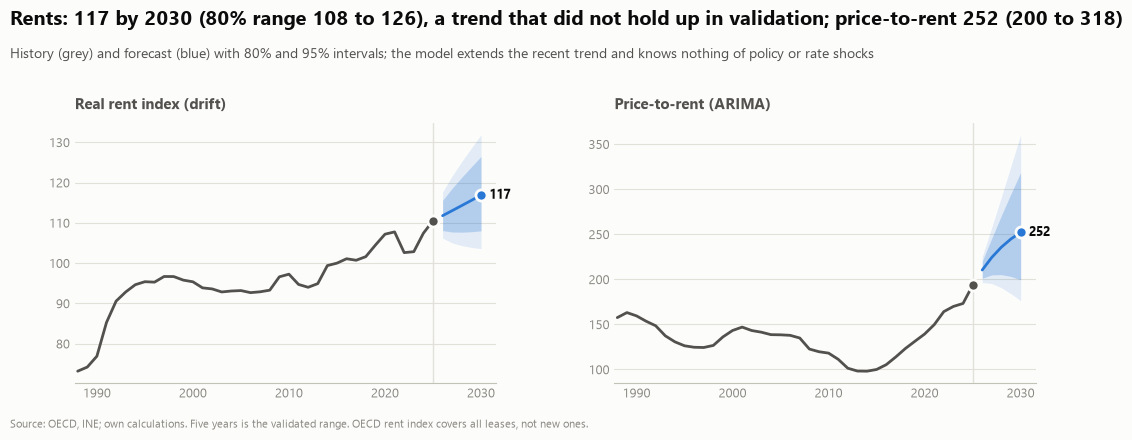

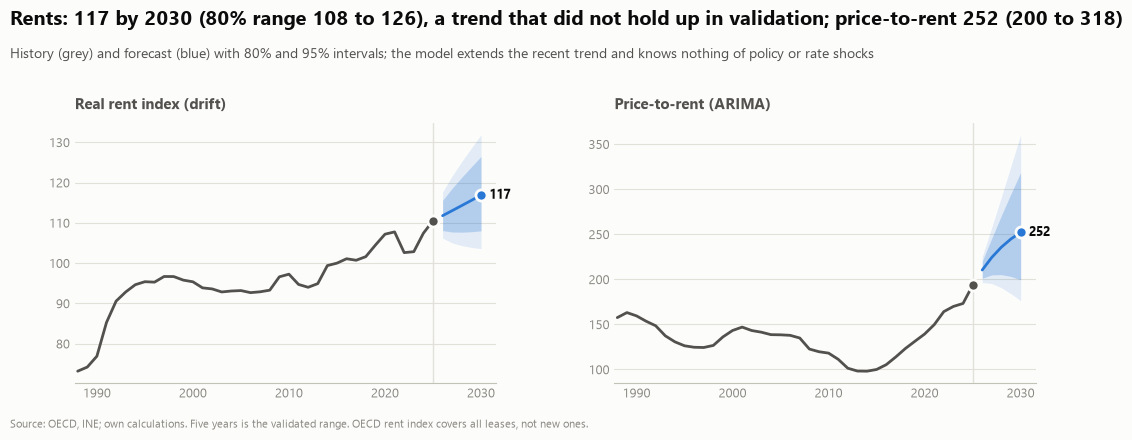

In [6]:
fan = {name: np.exp(fc.ANNUAL_METHODS[chosen[name]](s, HORIZON)) for name, s in series.items()}
rows = [f.reset_index(names="period").assign(series=n, method=chosen[n]) for n, f in fan.items()]
forecast_table = pd.concat(rows, ignore_index=True)
forecast_table["period"] = forecast_table["period"].astype(str)
style.save_table(forecast_table.round(2), "p4", "rent_forecast")

panels = []
for name, s in series.items():
    hist = np.exp(s)
    f = fan[name].copy()
    f.index = f.index.year
    panels.append(
        {
            "title": f"{name} ({chosen[name]})",
            "history": pd.Series(hist.to_numpy(), index=hist.index.year),
            "forecast": f,
            "unit_fmt": "{:.0f}",
        }
    )
rent_end, ptr_end = fan["Real rent index"].iloc[-1], fan["Price-to-rent"].iloc[-1]
panels[0]["headline"] = (
    f"Rents: {rent_end['mean']:.0f} by {rent_end.name} (80% range {rent_end['lo80']:.0f} to {rent_end['hi80']:.0f}), a trend that did not hold up in validation;"
    f" price-to-rent {ptr_end['mean']:.0f} ({ptr_end['lo80']:.0f} to {ptr_end['hi80']:.0f})"
)
fig = charts.forecast_fans(
    panels,
    step=10,
    footer="Source: OECD, INE; own calculations. Five years is the validated range. OECD rent index covers all leases, not new ones.",
)
style.save_fig(fig, "p4", "rent_forecast")
fig

## Step 5 — Is the rent index the rent a new tenant pays?
INE's median rent per m² of *new* leases (municipal, 2020 to 2024) against the OECD index of all leases over the same years,
both real. Municipalities with a published rent in both years.

In [7]:
panel = build_panel.read("panel_municipality_year")
wide = panel.pivot(index="muni_code", columns="year", values="rent_sqm_eur_real")
both = wide[[2020, 2024]].dropna()
new_leases = float(np.median(np.log(both[2024] / both[2020])))
index_all = float(
    np.log(
        annual.loc[pd.Period("2024", "Y"), "rent_real_b2015"]
        / annual.loc[pd.Period("2020", "Y"), "rent_real_b2015"]
    )
)
cross = pd.DataFrame(
    {
        "measure": [
            "INE median rent per m2, new leases (median municipality)",
            "OECD rent index, all leases",
        ],
        "real_change_2020_2024_pct": [100 * np.expm1(new_leases), 100 * np.expm1(index_all)],
        "municipalities_n": [len(both), np.nan],
    }
).round(1)
style.save_table(cross, "p4", "rent_measures_2020_2024")
cross

,measure,real_change_2020_2024_pct,municipalities_n
0,"INE median rent per m2, new leases (median mun...",24.0,191.0
1,"OECD rent index, all leases",0.2,NaN


## Findings

1. **No model reliably forecasts real rents.** ETS and ARIMA are 7% to 45% worse than no change at every horizon (mean RMSE
   relative to naive 1.23 and 1.26). Drift is the only one that beats it by the rule (0.87, and 0.78 without the 2020-21
   origins) but with a 15-year first window it does not (1.03, 0.97): the gain is not stable. The real rent index moved
   between 93 and 111 (2015 = 100) since 1995, with no trend that a model learns reliably.
2. **Price-to-rent can be forecast, with intervals that are too narrow.** ARIMA cuts the naive RMSE by 28% (0.72 of naive, 0.73 with the
   shorter window, 0.76 without 2020-21), ETS by 15%; drift is worse than no change (1.07). ARIMA's 80% intervals hold 56% of outcomes
   (95%: 89%), naive's 22%.
3. **Forecast to 2030.** Real rent index 110.5 (2025) to 116.9 (drift, 80% range 108.0 to 126.5); price-to-rent 193 to 252 (ARIMA, 200 to
   318). The second extends the 2015-2025 climb with understated intervals: read it as "no sign of reversal", not as a level.
4. **The rent index is not the rent a new tenant pays.** Over 2020 to 2024 the OECD index of all leases rose 0.2% in real terms; INE's
   median rent per m2 of new leases rose 24.0% in the median of 191 municipalities. The forecast above is for the stock
   of leases, which are regulated and move slowly.

**Limits.** 38 annual points and one regime change (the 2012 rent-law reform) in the sample; national only; no series of new-lease rents
before 2020 to forecast the quantity that matters to a tenant. Not wired into the simulator: a forecast of the slow index would not tell
a tenant's affordability, and the new-lease series is too short to validate.